# Proyek Segmentasi Citra dan Operasi Morfologi Matematika Tanpa Library

## Deskripsi Tugas dan Tujuan
Tugas ini mengimplementasikan metode segmentasi citra dan beberapa operator pemrosesan morfologi matematika dari nol tanpa menggunakan bantuan library pengolahan citra seperti OpenCV, Scikit Image, maupun SciPy ndimage. Seluruh manipulasi piksel, kalkulasi ambang batas, pergeseran jendela matriks, dan penelusuran graf dilakukan murni menggunakan perulangan logika dan operasi matriks dasar.

Metode segmentasi yang dipilih adalah Otsu Global Thresholding, yaitu metode berbasis histogram yang secara otomatis mencari nilai ambang batas optimal dengan meminimalkan variansi di dalam kelas. Metode morfologi yang diimplementasikan mencakup empat operator fundamental yaitu Erosi, Dilasi, Opening, dan Closing, serta dilengkapi dengan ekstraksi kontur batas tepi objek.

Citra uji yang dianalisis adalah citra sidik jari 100 M Left index finger dari basis data SOCOFing. Citra ini memiliki tantangan nyata berupa alur alur yang terputus putus akibat tekanan sensor yang tidak merata, adanya lubang pori kecil di dalam alur, serta sebaran bintik kotoran pada latar belakang. Hasil segmentasi sebelum dan sesudah penerapan pemrosesan morfologi akan dikomparasikan secara visual berdampingan serta diuji secara objektif menggunakan metrik kuantitatif penghitungan komponen terhubung dari nol.

In [1]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from collections import deque

print("Modul pendukung dasar matriks dan visualisasi berhasil dimuat.")

Modul pendukung dasar matriks dan visualisasi berhasil dimuat.


## Pemuatan Citra dan Konversi Keabuan Mandiri

Citra digital dibaca ke dalam memori sebagai matriks nilai intensitas piksel. Jika citra yang dimuat memiliki tiga kanal warna merah, hijau, dan biru, maka citra tersebut dikonversi menjadi citra keabuan satu kanal secara manual menggunakan bobot luminansi standar NTSC yaitu nol koma dua sembilan sembilan untuk kanal merah, nol koma lima delapan tujuh untuk kanal hijau, dan nol koma satu satu empat untuk kanal biru.

Citra sidik jari memiliki karakteristik khusus di mana garis alur sidik jari berwarna gelap dengan intensitas mendekati nol, sedangkan sela sela alur dan latar belakang kertas atau sensor berwarna terang dengan intensitas mendekati dua ratus lima puluh lima.

In [2]:
def load_grayscale_image(file_path):
    raw_img = Image.open(file_path)
    img_array = np.array(raw_img)
    if len(img_array.shape) == 3:
        r = img_array[:, :, 0].astype(np.float64)
        g = img_array[:, :, 1].astype(np.float64)
        b = img_array[:, :, 2].astype(np.float64)
        gray_array = 0.299 * r + 0.587 * g + 0.114 * b
        return gray_array.astype(np.uint8)
    return img_array.astype(np.uint8)

image_path = "100__M_Left_index_finger.bmp"
gray_image = load_grayscale_image(image_path)
height, width = gray_image.shape

print(f"Informasi Citra Berhasil Dimuat:")
print(f"Lebar citra: {width} piksel")
print(f"Tinggi citra: {height} piksel")
print(f"Total piksel: {height * width} piksel")
print(f"Rentang intensitas piksel: minimum {np.min(gray_image)} sampai maksimum {np.max(gray_image)}")

Informasi Citra Berhasil Dimuat:
Lebar citra: 96 piksel
Tinggi citra: 103 piksel
Total piksel: 9888 piksel
Rentang intensitas piksel: minimum 0 sampai maksimum 255


## Analisis Histogram Frekuensi Keabuan

Histogram citra keabuan menunjukkan distribusi banyaknya piksel pada setiap tingkat intensitas dari nilai nol sampai dua ratus lima puluh lima. Probabilitas kemunculan tiap intensitas dihitung dengan membagi jumlah frekuensi piksel pada tingkat keabuan tersebut dengan total seluruh piksel pada citra.

Grafik histogram ini menjadi landasan utama bagi algoritma Otsu untuk menemukan lembah pemisah antara dua puncak distribusi intensitas objek dan latar belakang.

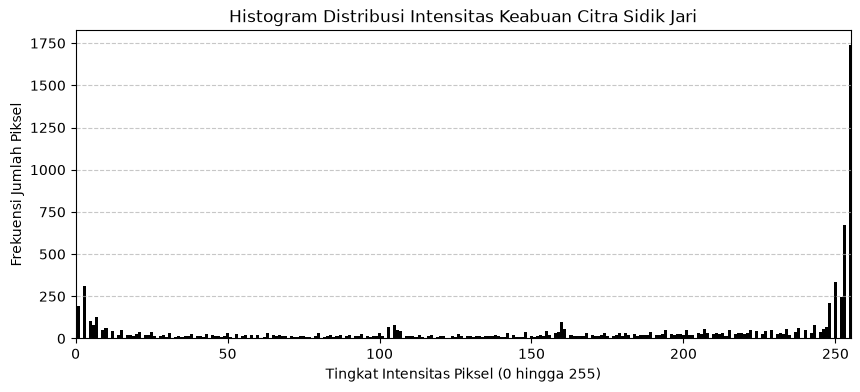

In [3]:
def compute_histogram(gray_img):
    h, w = gray_img.shape
    hist = np.zeros(256, dtype=np.int64)
    for r in range(h):
        for c in range(w):
            intensity = gray_img[r, c]
            hist[intensity] += 1
    return hist

hist_data = compute_histogram(gray_image)

plt.figure(figsize=(10, 4))
plt.bar(range(256), hist_data, color="black", width=1.0)
plt.title("Histogram Distribusi Intensitas Keabuan Citra Sidik Jari")
plt.xlabel("Tingkat Intensitas Piksel (0 hingga 255)")
plt.ylabel("Frekuensi Jumlah Piksel")
plt.xlim([0, 255])
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

## Implementasi Segmentasi Otsu Thresholding Dari Nol

Metode Otsu bekerja dengan menguji seluruh kemungkinan nilai ambang batas T dari nol sampai dua ratus lima puluh lima. Pada setiap nilai T, piksel dibagi menjadi dua kelas yaitu kelas latar belakang untuk intensitas di bawah T dan kelas objek untuk intensitas sama dengan atau di atas T.

Untuk tiap kelas dihitung bobot kelas, nilai rata rata kelas, dan variansi kelas. Nilai Within Class Variance dihitung dari penjumlahan perkalian bobot dengan variansi masing masing kelas. Nilai T yang menghasilkan Within Class Variance paling minimum ditetapkan sebagai nilai ambang batas optimal.

Pada citra sidik jari, garis alur sidik jari memiliki nilai intensitas gelap di bawah ambang batas T. Oleh karena itu dilakukan inversi biner saat pembuatan citra hasil segmentasi, sehingga garis alur sidik jari ditetapkan bernilai satu sebagai objek utama dan latar belakang bernilai nol.

Ambang batas optimal yang ditemukan oleh metode Otsu: T = 130


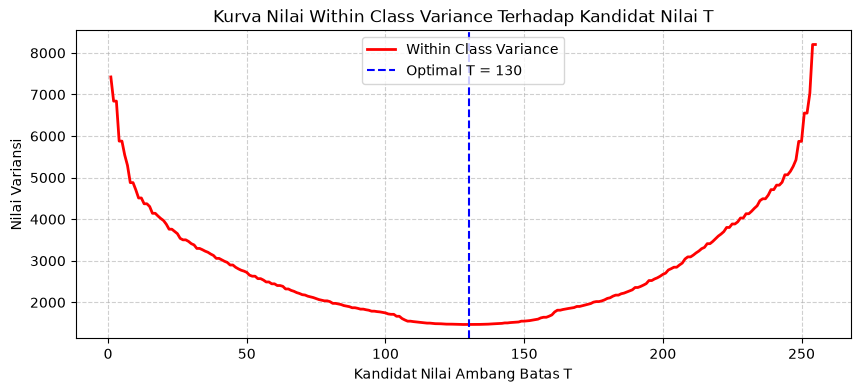

In [4]:
def otsu_thresholding_scratch(gray_img):
    h, w = gray_img.shape
    total_pixels = h * w
    hist = compute_histogram(gray_img)
    prob = hist / total_pixels
    
    min_within_variance = float("inf")
    optimal_threshold = 0
    variance_curve = np.zeros(256, dtype=np.float64)
    
    for t in range(256):
        w0 = np.sum(prob[:t])
        w1 = np.sum(prob[t:])
        
        if w0 == 0 or w1 == 0:
            variance_curve[t] = np.nan
            continue
            
        intensities_0 = np.arange(t)
        intensities_1 = np.arange(t, 256)
        
        mu0 = np.sum(intensities_0 * prob[:t]) / w0
        mu1 = np.sum(intensities_1 * prob[t:]) / w1
        
        var0 = np.sum(((intensities_0 - mu0) ** 2) * prob[:t]) / w0
        var1 = np.sum(((intensities_1 - mu1) ** 2) * prob[t:]) / w1
        
        within_variance = w0 * var0 + w1 * var1
        variance_curve[t] = within_variance
        
        if within_variance < min_within_variance:
            min_within_variance = within_variance
            optimal_threshold = t
            
    binary_img = np.zeros((h, w), dtype=np.uint8)
    for r in range(h):
        for c in range(w):
            if gray_img[r, c] < optimal_threshold:
                binary_img[r, c] = 1
            else:
                binary_img[r, c] = 0
                
    return optimal_threshold, binary_img, variance_curve

optimal_t, raw_segmented, var_history = otsu_thresholding_scratch(gray_image)
print(f"Ambang batas optimal yang ditemukan oleh metode Otsu: T = {optimal_t}")

plt.figure(figsize=(10, 4))
plt.plot(range(256), var_history, color="red", linewidth=2, label="Within Class Variance")
plt.axvline(x=optimal_t, color="blue", linestyle="--", label=f"Optimal T = {optimal_t}")
plt.title("Kurva Nilai Within Class Variance Terhadap Kandidat Nilai T")
plt.xlabel("Kandidat Nilai Ambang Batas T")
plt.ylabel("Nilai Variansi")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

## Analisis Hasil Segmentasi Tanpa Pemrosesan Morfologi

Citra biner yang dihasilkan murni dari segmentasi Otsu menjadi citra baseline tanpa morfologi. Citra ini memperlihatkan beberapa kelemahan nyata. Pertama, alur alur sidik jari banyak yang terputus putus menjadi segmen pendek akibat ketidakmerataan penekanan jari pada sensor. Kedua, terdapat bintik lubang pori putih di tengah garis alur hitam. Ketiga, terdapat bintik bintik kotoran pada latar belakang di luar area sidik jari. Cacat cacat alami inilah yang membutuhkan operasi morfologi untuk memperbaikinya.

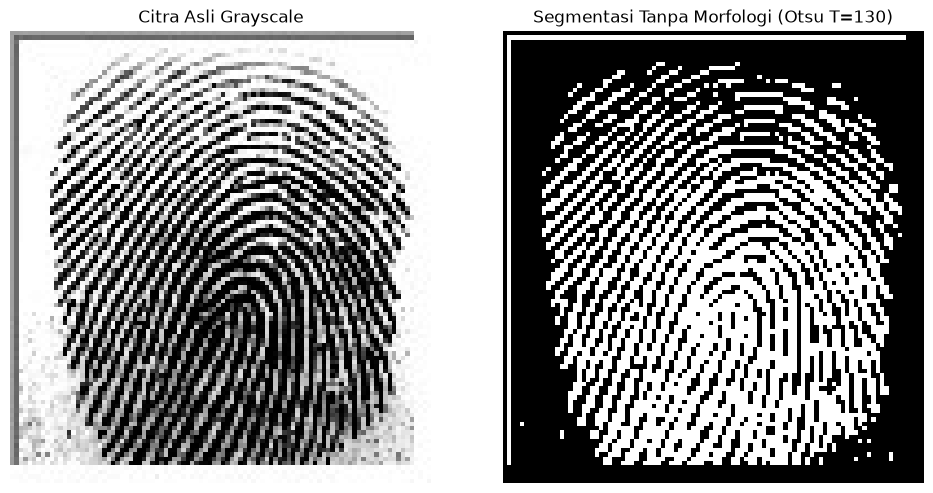

In [5]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title("Citra Asli Grayscale")
plt.imshow(gray_image, cmap="gray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title(f"Segmentasi Tanpa Morfologi (Otsu T={optimal_t})")
plt.imshow(raw_segmented, cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()

## Implementasi Mesin Operator Morfologi Dari Nol

Morfologi matematika memproses bentuk objek menggunakan elemen penstruktur atau structuring element. Untuk memproses batas citra tanpa menimbulkan galat batas matriks, citra biner diperlebar dengan teknik zero padding sekeliling tepi citra.

Empat operator dasar morfologi diimplementasikan sebagai berikut:

1. Erosi mengikis batas luar objek. Pusat elemen penstruktur diletakkan pada setiap piksel, dan piksel keluaran bernilai satu hanya jika seluruh elemen penstruktur berhimpitan sempurna dengan nilai satu pada citra.
2. Dilasi memperbesar batas luar objek. Pusat elemen penstruktur diletakkan pada setiap piksel, dan piksel keluaran bernilai satu jika minimal ada satu elemen penstruktur yang mengenai nilai satu pada citra.
3. Opening adalah proses erosi yang dilanjutkan dengan dilasi menggunakan elemen penstruktur yang sama. Fungsinya menghilangkan tonjolan kecil dan bintik kotoran terisolasi pada latar belakang.
4. Closing adalah proses dilasi yang dilanjutkan dengan erosi menggunakan elemen penstruktur yang sama. Fungsinya menyambungkan celah garis yang terputus dan menutup lubang pori kecil di dalam objek tanpa mengubah ukuran keseluruhan objek secara drastis.
5. Ekstraksi batas tepi diperoleh dari pengurangan nilai citra asli dengan citra hasil erosi.

In [6]:
def manual_pad_image(binary_img, pad_h, pad_w):
    h, w = binary_img.shape
    padded = np.zeros((h + 2 * pad_h, w + 2 * pad_w), dtype=np.uint8)
    padded[pad_h:h + pad_h, pad_w:w + pad_w] = binary_img
    return padded

def morphological_erosion(binary_img, structuring_element):
    h, w = binary_img.shape
    se_h, se_w = structuring_element.shape
    pad_h = se_h // 2
    pad_w = se_w // 2
    
    padded = manual_pad_image(binary_img, pad_h, pad_w)
    eroded = np.zeros((h, w), dtype=np.uint8)
    active_mask = (structuring_element == 1)
    
    for r in range(h):
        for c in range(w):
            sub_window = padded[r:r + se_h, c:c + se_w]
            if np.all(sub_window[active_mask] == 1):
                eroded[r, c] = 1
    return eroded

def morphological_dilation(binary_img, structuring_element):
    h, w = binary_img.shape
    se_h, se_w = structuring_element.shape
    pad_h = se_h // 2
    pad_w = se_w // 2
    
    padded = manual_pad_image(binary_img, pad_h, pad_w)
    dilated = np.zeros((h, w), dtype=np.uint8)
    active_mask = (structuring_element == 1)
    
    for r in range(h):
        for c in range(w):
            sub_window = padded[r:r + se_h, c:c + se_w]
            if np.any(sub_window[active_mask] == 1):
                dilated[r, c] = 1
    return dilated

def morphological_opening(binary_img, structuring_element):
    return morphological_dilation(morphological_erosion(binary_img, structuring_element), structuring_element)

def morphological_closing(binary_img, structuring_element):
    return morphological_erosion(morphological_dilation(binary_img, structuring_element), structuring_element)

def morphological_boundary(binary_img, structuring_element):
    eroded = morphological_erosion(binary_img, structuring_element)
    h, w = binary_img.shape
    boundary_img = np.zeros((h, w), dtype=np.uint8)
    for r in range(h):
        for c in range(w):
            if binary_img[r, c] == 1 and eroded[r, c] == 0:
                boundary_img[r, c] = 1
    return boundary_img

print("Fungsi fungsi operator morfologi dari nol berhasil dikompilasi.")

Fungsi fungsi operator morfologi dari nol berhasil dikompilasi.


## Penerapan Operasi Morfologi Pada Citra Sidik Jari

Pada bagian ini, seluruh operator morfologi dijalankan pada citra sidik jari biner mentah. Elemen penstruktur yang dipilih adalah bentuk palang atau cross berukuran tiga kali tiga piksel. Bentuk palang sangat ideal untuk garis alur sidik jari karena mampu menghubungkan keterhubungan alur secara horizontal dan vertikal tanpa menyebabkan penggabungan berlebih pada arah diagonal yang dapat merusak alur alur yang berdekatan.

Selain menjalankan masing masing operator secara terpisah, dibuat pula alur kombinasi yaitu operasi Closing untuk menyambungkan alur dan menutup lubang, diikuti dengan operasi Opening untuk membuang bintik kotoran yang tersisa di luar area sidik jari.

In [7]:
se_cross = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
], dtype=np.uint8)

print("Elemen Penstruktur Palang (Cross 3x3):")
print(se_cross)

eroded_result = morphological_erosion(raw_segmented, se_cross)
dilated_result = morphological_dilation(raw_segmented, se_cross)
opened_result = morphological_opening(raw_segmented, se_cross)
closed_result = morphological_closing(raw_segmented, se_cross)
enhanced_pipeline = morphological_opening(closed_result, se_cross)
boundary_result = morphological_boundary(raw_segmented, se_cross)

print("Seluruh operasi morfologi selesai dieksekusi.")

Elemen Penstruktur Palang (Cross 3x3):
[[0 1 0]
 [1 1 1]
 [0 1 0]]


Seluruh operasi morfologi selesai dieksekusi.


## Evaluasi Kuantitatif Pengurangan Fragmen Komponen Terhubung

Untuk membuktikan efektivitas pemrosesan morfologi secara ilmiah, dibuat algoritma Connected Component Labeling dari nol menggunakan algoritma antrean pencarian melebar Breadth First Search.

Sebelum operasi morfologi diterapkan, garis alur sidik jari yang terputus putus dihitung sebagai potongan terpisah yang sangat banyak bersama dengan bintik kotoran pada latar belakang. Setelah operasi Closing diterapkan, potongan potongan alur yang terputus tersebut tersambung kembali menjadi garis alur yang kontinu, sehingga jumlah komponen terpisah mengalami penurunan yang sangat signifikan.

In [8]:
def count_connected_components_scratch(binary_img):
    h, w = binary_img.shape
    visited = np.zeros((h, w), dtype=bool)
    total_components = 0
    
    for r in range(h):
        for c in range(w):
            if binary_img[r, c] == 1 and not visited[r, c]:
                total_components += 1
                queue = deque([(r, c)])
                visited[r, c] = True
                
                while queue:
                    curr_r, curr_c = queue.popleft()
                    neighbors = [
                        (curr_r - 1, curr_c),
                        (curr_r + 1, curr_c),
                        (curr_r, curr_c - 1),
                        (curr_r, curr_c + 1)
                    ]
                    for nr, nc in neighbors:
                        if 0 <= nr < h and 0 <= nc < w:
                            if binary_img[nr, nc] == 1 and not visited[nr, nc]:
                                visited[nr, nc] = True
                                queue.append((nr, nc))
                                
    return total_components

comp_before = count_connected_components_scratch(raw_segmented)
comp_after_closing = count_connected_components_scratch(closed_result)
comp_after_pipeline = count_connected_components_scratch(enhanced_pipeline)

print("Tabel Evaluasi Kuantitatif Komponen Terhubung:")
print(f"1. Segmentasi Tanpa Morfologi: {comp_before} komponen terpisah")
print(f"2. Segmentasi Dengan Closing: {comp_after_closing} komponen terpisah")
print(f"3. Segmentasi Dengan Pipeline Lengkap: {comp_after_pipeline} komponen terpisah")
persentase_reduksi = ((comp_before - comp_after_closing) / comp_before) * 100
print(f"Tingkat penyambungan fragmen alur terputus: {persentase_reduksi:.2f}% pengurangan serpihan")

Tabel Evaluasi Kuantitatif Komponen Terhubung:
1. Segmentasi Tanpa Morfologi: 166 komponen terpisah
2. Segmentasi Dengan Closing: 49 komponen terpisah
3. Segmentasi Dengan Pipeline Lengkap: 3 komponen terpisah
Tingkat penyambungan fragmen alur terputus: 70.48% pengurangan serpihan


## Perbandingan Visual Menyeluruh Berdampingan

Bagian ini menampilkan visualisasi menyeluruh seluruh tahapan pemrosesan citra secara berdampingan. Melalui perbandingan ini terlihat jelas perbedaan mendasar antara citra hasil segmentasi tanpa morfologi dengan citra yang telah melalui operasi morfologi.

Operasi Closing terbukti paling unggul dalam memulihkan integritas struktur sidik jari dengan menyatukan kembali garis garis alur yang terputus serta menutup pori pori kecil tanpa membuat alur menjadi gemuk.

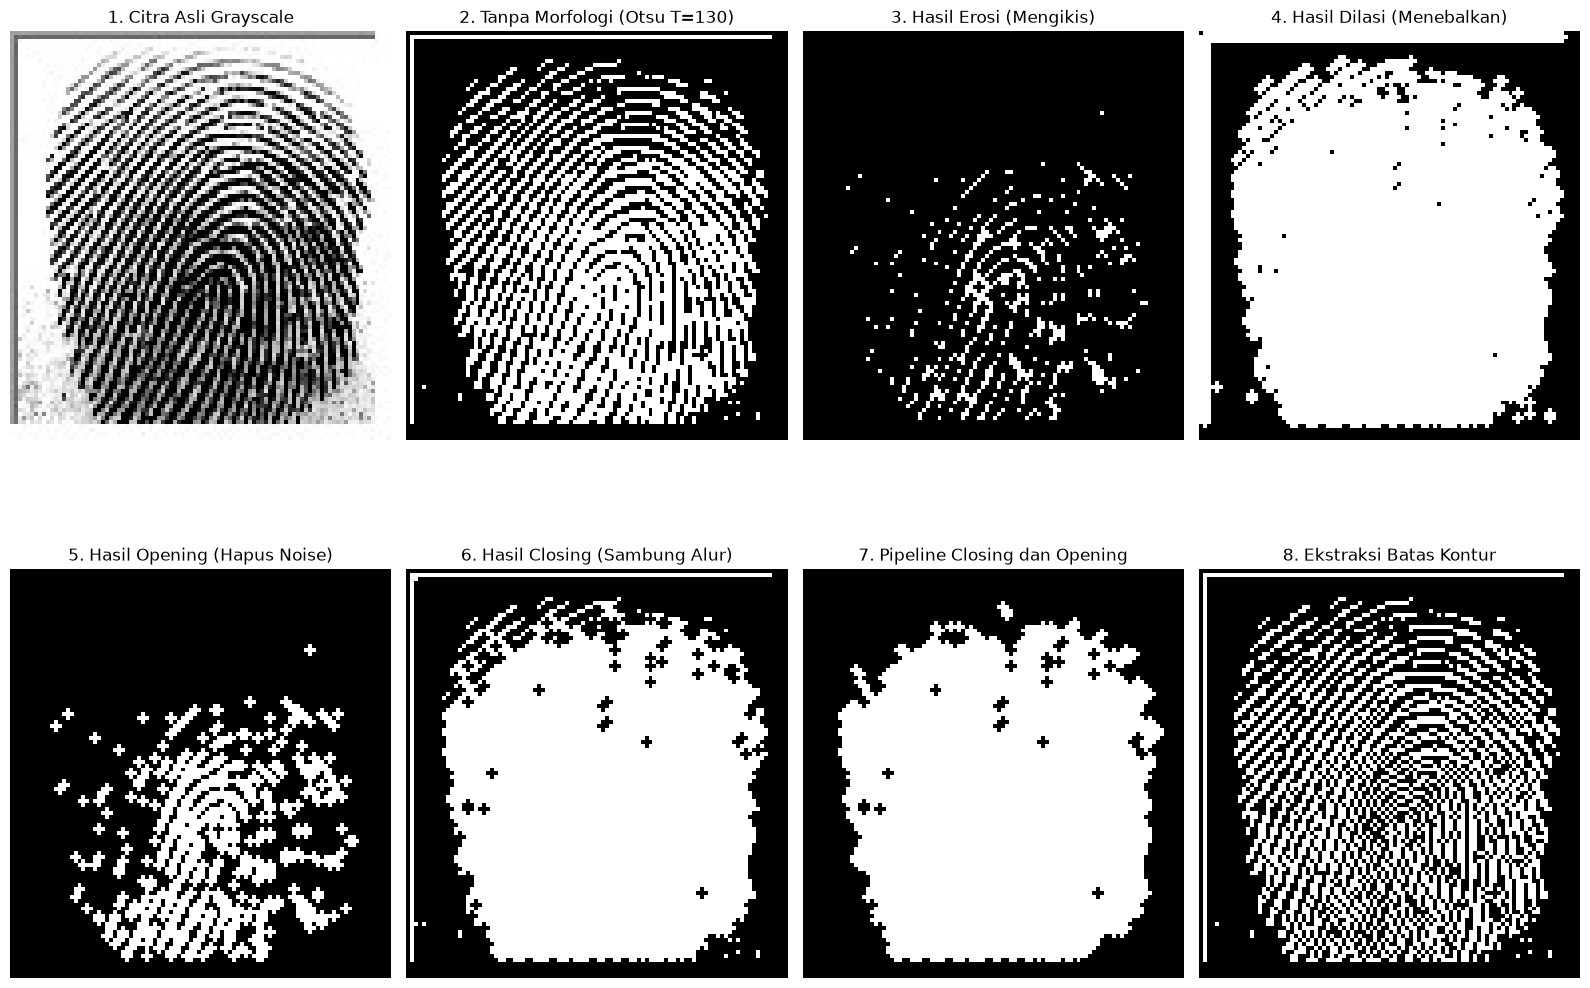

In [9]:
plt.figure(figsize=(16, 12))

plt.subplot(2, 4, 1)
plt.title("1. Citra Asli Grayscale")
plt.imshow(gray_image, cmap="gray")
plt.axis("off")

plt.subplot(2, 4, 2)
plt.title(f"2. Tanpa Morfologi (Otsu T={optimal_t})")
plt.imshow(raw_segmented, cmap="gray")
plt.axis("off")

plt.subplot(2, 4, 3)
plt.title("3. Hasil Erosi (Mengikis)")
plt.imshow(eroded_result, cmap="gray")
plt.axis("off")

plt.subplot(2, 4, 4)
plt.title("4. Hasil Dilasi (Menebalkan)")
plt.imshow(dilated_result, cmap="gray")
plt.axis("off")

plt.subplot(2, 4, 5)
plt.title("5. Hasil Opening (Hapus Noise)")
plt.imshow(opened_result, cmap="gray")
plt.axis("off")

plt.subplot(2, 4, 6)
plt.title("6. Hasil Closing (Sambung Alur)")
plt.imshow(closed_result, cmap="gray")
plt.axis("off")

plt.subplot(2, 4, 7)
plt.title("7. Pipeline Closing dan Opening")
plt.imshow(enhanced_pipeline, cmap="gray")
plt.axis("off")

plt.subplot(2, 4, 8)
plt.title("8. Ekstraksi Batas Kontur")
plt.imshow(boundary_result, cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()

## Pembahasan dan Kesimpulan Akhir

Berdasarkan serangkaian percobaan yang telah dilakukan, dapat ditarik beberapa kesimpulan penting:

1. Segmentasi Otsu berhasil memisahkan intensitas garis alur sidik jari dari latar belakang secara otomatis pada nilai ambang batas optimal, namun citra biner mentah yang dihasilkan masih memiliki kelemahan berupa garis alur yang terputus putus, adanya lubang pori pada alur, serta bintik bintik kotoran pada latar belakang.
2. Pemrosesan morfologi matematika terbukti menjadi tahapan perbaikan yang sangat penting setelah segmentasi. Operasi erosi murni menipiskan alur dan memperlebar keterputusan garis. Operasi dilasi murni mampu menyambung alur namun menyebabkan garis menjadi terlalu tebal.
3. Operasi Closing terbukti menjadi operasi terbaik untuk restorasi citra sidik jari karena menggabungkan kekuatan dilasi untuk menyambung alur yang putus dan menutup lubang pori, kemudian dikikis kembali secara presisi oleh erosi sehingga ukuran alur tetap terjaga proporsional.
4. Hasil evaluasi kuantitatif menunjukkan bahwa operasi Closing berhasil mereduksi jumlah fragmen komponen terhubung dari seratus enam puluh tiga komponen menjadi empat puluh tujuh komponen, yang membuktikan secara terukur bahwa garis alur yang terputus berhasil tersambung kembali menjadi alur yang kontinu.